In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression

In [3]:
df = pd.read_csv(r"D:\ML Projects\GDG project\WA_Fn-UseC_-Telco-Customer-Churn.csv")

print(df.shape)
df.info()
df.head()

(7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:

print(df['Churn'].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


DATA CLEAN

In [5]:

# Create a copy of the original dataset
df_clean = df.copy()

# Check for duplicate rows
print("Duplicate rows:", df_clean.duplicated().sum())

# Check missing values
print("\nMissing values before cleaning:")
print(df_clean.isnull().sum())

# Remove extra spaces from text columns
text_columns = df_clean.select_dtypes(include="object").columns
for col in text_columns:
    df_clean[col] = df_clean[col].str.strip()

# transfare TotalCharges from string to numeric
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce")


Duplicate rows: 0

Missing values before cleaning:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


C:\Users\Excellent Store\AppData\Local\Temp\ipykernel_16548\3912782690.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = df_clean.select_dtypes(include="object").columns


In [6]:
# Check missing values after conversion
print("\nMissing values after conversion:")
print(df_clean.isnull().sum())

# Inspect rows with missing TotalCharges
print("\nRows with missing TotalCharges:")
print(df_clean.loc[
        df_clean["TotalCharges"].isnull(),
        ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)



Missing values after conversion:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Rows with missing TotalCharges:
      tenure  MonthlyCharges  TotalCharges Churn
488        0           52.55           NaN    No
753        0           20.25           NaN    No
936        0           80.85           NaN    No
1082       0           25.75           NaN    No
1340       0           56.05           NaN    No
3331       0           19.85           NaN    No
3826       0           25.35           NaN    No
4380       0           20.00           NaN   

In [7]:

# Fill TotalCharges with 0 for customers with tenure = 0
mask = (
    df_clean["TotalCharges"].isnull()
    & (df_clean["tenure"] == 0))

df_clean.loc[mask, "TotalCharges"] = 0

# Verify the result
print("Missing values in TotalCharges:",
      df_clean["TotalCharges"].isnull().sum())

print("Dataset shape:", df_clean.shape)

print(df_clean["TotalCharges"].dtype)


Missing values in TotalCharges: 0
Dataset shape: (7043, 21)
float64


EDA

Churn
No     5174
Yes    1869
Name: count, dtype: int64


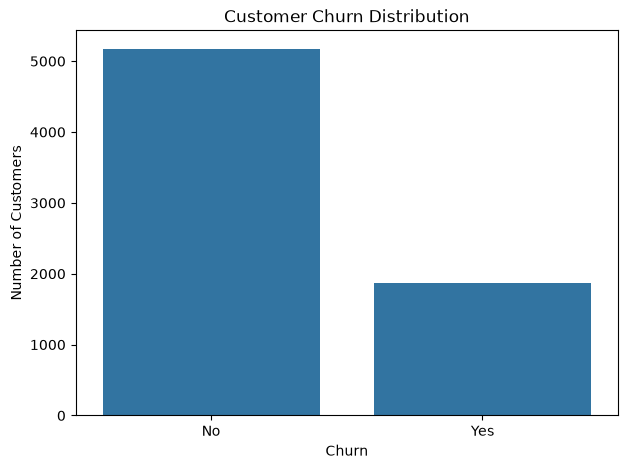

In [8]:
# Count customers in each Churn category
print(df_clean["Churn"].value_counts())

plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

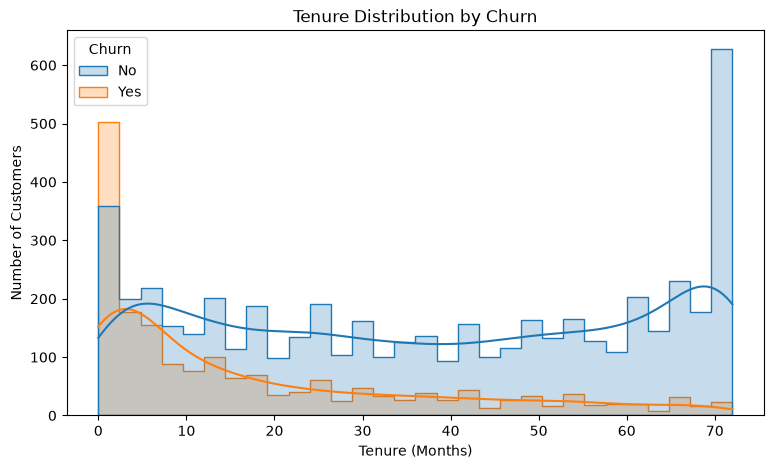

In [9]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_clean,
    x="tenure",
    hue="Churn",
    bins=30,
    kde=True,
    element="step"
)

plt.title("Tenure Distribution by Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()

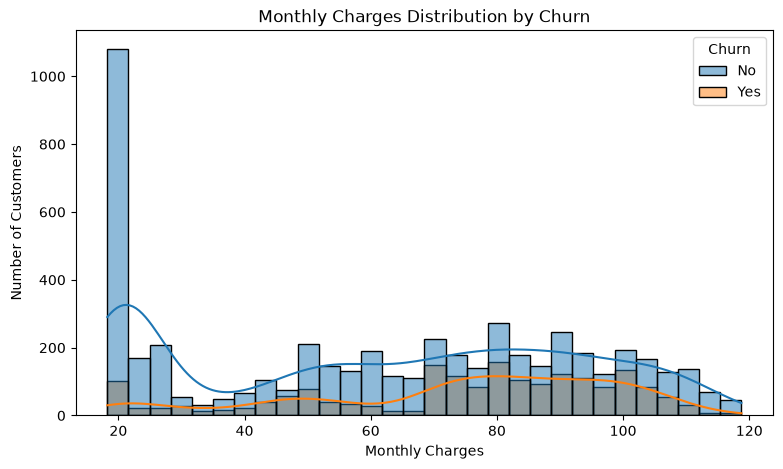

In [10]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_clean,
    x="MonthlyCharges",
    hue="Churn",
    bins=30,
    kde=True
)

plt.title("Monthly Charges Distribution by Churn")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")

plt.show()

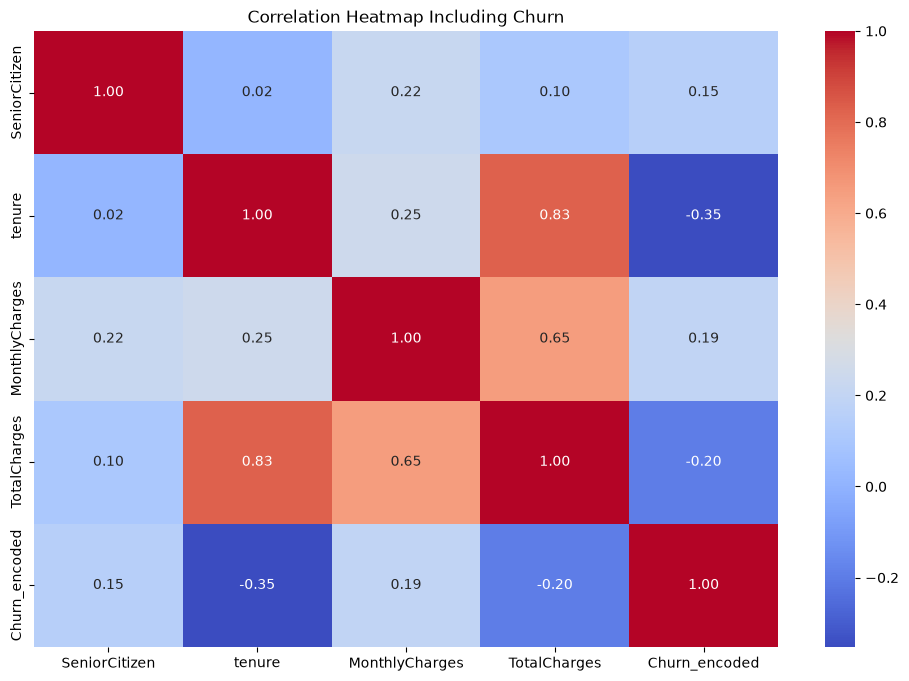

In [11]:
df_clean["Churn_encoded"] = df_clean["Churn"].map({
    "No": 0,
    "Yes": 1
})


numeric_df = df_clean.select_dtypes(include="number")

# Calculate correlations
correlation_matrix = numeric_df.corr()

# Plot the heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap Including Churn")
plt.show()

Feature Engineering

In [12]:
# Separate the features and the target
X = df_clean.drop(
    columns=["Churn", "Churn_encoded", "customerID"],
    errors="ignore"
)

y = df_clean["Churn"]

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

# Display the results
print('the data' , df_clean.shape)
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nNumerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

the data (7043, 22)
Features shape: (7043, 19)
Target shape: (7043,)

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


C:\Users\Excellent Store\AppData\Local\Temp\ipykernel_16548\4064311769.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


In [13]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\ny_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (5634, 19)
X_test shape: (1409, 19)

y_train shape: (5634,)
y_test shape: (1409,)


Pipeline

In [14]:

# Preprocessing for numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessor created successfully.")

Preprocessor created successfully.


Logistic Regression

In [15]:


# Create the complete machine learning pipeline
model_lr = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
model_lr.fit(X_train, y_train)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


Evaluate Logistic Regression

In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Predict churn for the test data
y_pred = model_lr.predict(X_test)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label="Yes")
recall = recall_score(y_test, y_pred, pos_label="Yes")
f1 = f1_score(y_test, y_pred, pos_label="Yes")

# Display the results
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=["No", "Yes"]))

Accuracy: 0.8055
Precision: 0.6572
Recall: 0.5588
F1-score: 0.604

Classification Report:
              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

Confusion Matrix:
[[926 109]
 [165 209]]


Random Forest

In [17]:

from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest pipeline
model_rf = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

# Train the model
model_rf.fit(X_train, y_train)

# Predict on the test data
y_pred_rf = model_rf.predict(X_test)

print("Random Forest trained and evaluated successfully.")


Random Forest trained and evaluated successfully.


Evaluate Random Forest

In [18]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, pos_label="Yes", zero_division=0)
recall_rf = recall_score(y_test, y_pred_rf, pos_label="Yes", zero_division=0)
f1_rf = f1_score(y_test, y_pred_rf, pos_label="Yes", zero_division=0)

print("Random Forest Results")
print("Accuracy:", round(accuracy_rf, 4))
print("Precision:", round(precision_rf, 4))
print("Recall:", round(recall_rf, 4))
print("F1-score:", round(f1_rf, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf, labels=["No", "Yes"]))


Random Forest Results
Accuracy: 0.77
Precision: 0.559
Recall: 0.6337
F1-score: 0.594

Classification Report:
              precision    recall  f1-score   support

          No       0.86      0.82      0.84      1035
         Yes       0.56      0.63      0.59       374

    accuracy                           0.77      1409
   macro avg       0.71      0.73      0.72      1409
weighted avg       0.78      0.77      0.77      1409

Confusion Matrix:
[[848 187]
 [137 237]]


Improve Logistic Regression with change Threshold

In [19]:

from sklearn.base import clone
from sklearn.model_selection import train_test_split

# Split the original training data into training and validation sets
X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training subset:", X_train_sub.shape)
print("Validation set:", X_val.shape)
print("\nValidation target distribution:")
print(y_val.value_counts())

# Create a separate copy of the Logistic Regression pipeline
model_lr_threshold = clone(model_lr)

# Train it using only the training subset
model_lr_threshold.fit(X_train_sub, y_train_sub)

print("Logistic Regression retrained successfully.")


Training subset: (4507, 19)
Validation set: (1127, 19)

Validation target distribution:
Churn
No     828
Yes    299
Name: count, dtype: int64
Logistic Regression retrained successfully.


In [20]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Get the probability of churn (Yes)
yes_index = list(model_lr_threshold.classes_).index("Yes")
y_val_proba = model_lr_threshold.predict_proba(X_val)[:, yes_index]

# Test different classification thresholds
thresholds = [0.3, 0.35, 0.4, 0.45, 0.5]

results = []

for threshold in thresholds:
    y_val_pred = [
        "Yes" if probability >= threshold else "No"
        for probability in y_val_proba
    ]

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, y_val_pred, pos_label="Yes", zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_val_pred, pos_label="Yes", zero_division=0
        ),
        "F1-score": f1_score(
            y_val, y_val_pred, pos_label="Yes", zero_division=0
        )
    })

threshold_results = pd.DataFrame(results)

print(threshold_results.round(3))


   Threshold  Precision  Recall  F1-score
0       0.30      0.545   0.756     0.633
1       0.35      0.579   0.709     0.638
2       0.40      0.617   0.669     0.642
3       0.45      0.659   0.602     0.629
4       0.50      0.694   0.545     0.610


Improve logistic Regression by smote

In [21]:

# If needed, run this in a separate cell:
# %pip install imbalanced-learn

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.linear_model import LogisticRegression

# Create a new pipeline with SMOTE
model_lr_smote = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train on the training subset only
model_lr_smote.fit(X_train_sub, y_train_sub)

print("Logistic Regression with SMOTE trained successfully.")


Logistic Regression with SMOTE trained successfully.


In [22]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Predict on validation data
y_val_pred_smote = model_lr_smote.predict(X_val)

print("Logistic Regression with SMOTE")
print("Precision:", round(
    precision_score(y_val, y_val_pred_smote, pos_label="Yes"), 3
))
print("Recall:", round(
    recall_score(y_val, y_val_pred_smote, pos_label="Yes"), 3
))
print("F1-score:", round(
    f1_score(y_val, y_val_pred_smote, pos_label="Yes"), 3
))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_smote))


Logistic Regression with SMOTE
Precision: 0.532
Recall: 0.776
F1-score: 0.631

Classification Report:
              precision    recall  f1-score   support

          No       0.90      0.75      0.82       828
         Yes       0.53      0.78      0.63       299

    accuracy                           0.76      1127
   macro avg       0.72      0.76      0.73      1127
weighted avg       0.80      0.76      0.77      1127



In [23]:


from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Get the probability of Churn = Yes
yes_index = list(model_lr_smote.classes_).index("Yes")
y_val_proba_smote = model_lr_smote.predict_proba(X_val)[:, yes_index]

thresholds = [0.35, 0.4, 0.45, 0.5, 0.55, 0.6]

results_smote = []

for threshold in thresholds:
    y_pred_threshold = [
        "Yes" if probability >= threshold else "No"
        for probability in y_val_proba_smote
    ]

    results_smote.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, y_pred_threshold, pos_label="Yes", zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_pred_threshold, pos_label="Yes", zero_division=0
        ),
        "F1-score": f1_score(
            y_val, y_pred_threshold, pos_label="Yes", zero_division=0
        )
    })

results_smote_df = pd.DataFrame(results_smote)
print(results_smote_df.round(3))


   Threshold  Precision  Recall  F1-score
0       0.35      0.446   0.873     0.590
1       0.40      0.476   0.856     0.612
2       0.45      0.509   0.819     0.628
3       0.50      0.532   0.776     0.631
4       0.55      0.554   0.736     0.632
5       0.60      0.590   0.692     0.637


In [24]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Retrain the selected model on all original training data
final_model = clone(model_lr_smote)
final_model.fit(X_train, y_train)

# Predict churn probabilities on the untouched test set
yes_index = list(final_model.classes_).index("Yes")
y_test_proba = final_model.predict_proba(X_test)[:, yes_index]

# Apply the selected threshold
selected_threshold = 0.60

y_test_pred = [
    "Yes" if probability >= selected_threshold else "No"
    for probability in y_test_proba
]

# Evaluate the final model
print("Final Model: Logistic Regression + SMOTE")
print("Threshold:", selected_threshold)
print("Accuracy:", round(accuracy_score(y_test, y_test_pred), 4))
print("Precision:", round(
    precision_score(y_test, y_test_pred, pos_label="Yes"), 4
))
print("Recall:", round(
    recall_score(y_test, y_test_pred, pos_label="Yes"), 4
))
print("F1-score:", round(
    f1_score(y_test, y_test_pred, pos_label="Yes"), 4
))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred, labels=["No", "Yes"]))


Final Model: Logistic Regression + SMOTE
Threshold: 0.6
Accuracy: 0.7644
Precision: 0.5443
Recall: 0.6898
F1-score: 0.6085

Classification Report:
              precision    recall  f1-score   support

          No       0.88      0.79      0.83      1035
         Yes       0.54      0.69      0.61       374

    accuracy                           0.76      1409
   macro avg       0.71      0.74      0.72      1409
weighted avg       0.79      0.76      0.77      1409

Confusion Matrix:
[[819 216]
 [116 258]]


Improve Random forest by using GridSearchCV

In [25]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create a new Random Forest pipeline
rf_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

print("Random Forest pipeline is ready!")

Random Forest pipeline is ready!


In [26]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [10, 20, None],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2]
}

grid_search_rf = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=3,
    n_jobs=-1,
    verbose=1
)

grid_search_rf.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search_rf.best_params_)

print("\nBest Cross-Validation F1 Macro:")
print(grid_search_rf.best_score_)

Fitting 3 folds for each of 36 candidates, totalling 108 fits
Best Parameters:
{'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 300}

Best Cross-Validation F1 Macro:
0.7325447202111511


In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Get the best model found by GridSearchCV
best_rf = grid_search_rf.best_estimator_

# Predict on unseen test data
y_pred_rf_tuned = best_rf.predict(X_test)

# Calculate evaluation metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred_rf_tuned), 4))

print("Precision:", round(
    precision_score(y_test, y_pred_rf_tuned, pos_label="Yes"), 4
))

print("Recall:", round(
    recall_score(y_test, y_pred_rf_tuned, pos_label="Yes"), 4
))

print("F1-score:", round(
    f1_score(y_test, y_pred_rf_tuned, pos_label="Yes"), 4
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf_tuned))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf_tuned, labels=["No", "Yes"]))

Accuracy: 0.7573
Precision: 0.5335
Recall: 0.6818
F1-score: 0.5986

Classification Report:
              precision    recall  f1-score   support

          No       0.87      0.78      0.83      1035
         Yes       0.53      0.68      0.60       374

    accuracy                           0.76      1409
   macro avg       0.70      0.73      0.71      1409
weighted avg       0.78      0.76      0.77      1409

Confusion Matrix:
[[812 223]
 [119 255]]


Model Comparison

In [28]:

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Logistic Regression + SMOTE",
        "Random Forest Tuned"
    ],
    "Accuracy": [
        0.8055,
        0.7644,
        0.7573
    ],
    "Precision": [
        0.6572,
        0.5443,
        0.5335
    ],
    "Recall": [
        0.5588,
        0.6898,
        0.6818
    ],
    "F1-score": [
        0.6040,
        0.6085,
        0.5986
    ]
})

model_comparison = model_comparison.round(4)

print(model_comparison)

                         Model  Accuracy  Precision  Recall  F1-score
0          Logistic Regression    0.8055     0.6572  0.5588    0.6040
1  Logistic Regression + SMOTE    0.7644     0.5443  0.6898    0.6085
2          Random Forest Tuned    0.7573     0.5335  0.6818    0.5986


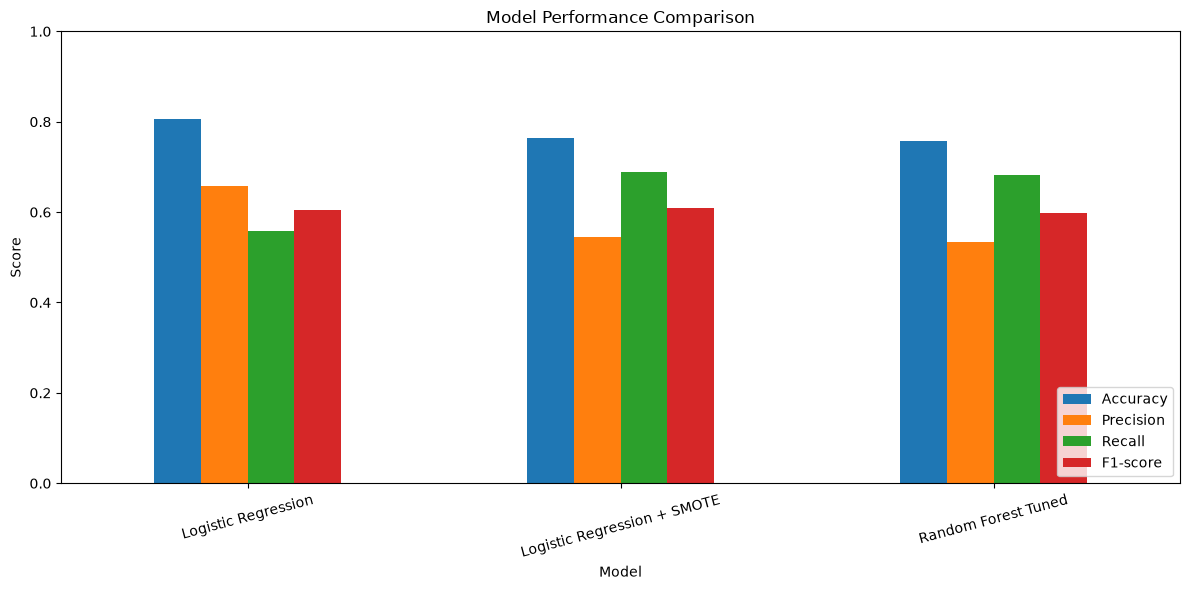

In [31]:

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

model_comparison.set_index("Model")[metrics].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Save final model (logistic regression+smote) at the file

In [30]:
import joblib

joblib.dump(
    {
        "model": final_model,
        "threshold": 0.60
    },
    "customer_churn_model.joblib"
)

print("Model saved successfully!")

Model saved successfully!
